# Categorical Feature Check — A Complete, Practical Guide

---

For a **numerical** feature we ask *"is the relationship a straight line?"* and reach for Pearson and
Spearman correlation (see the companion notebook, `LinearityCheck.ipynb`).

For a **categorical** feature that question makes no sense. There is nothing to be linear *about*.
Instead we ask:

> **Are the values of the target systematically different between the categories — and how strongly?**

This notebook works through the three statistics that answer that, then the two traps that catch
people out.

| # | Method | The question it answers | Robust to outliers? | Section |
|---|---|---|---|---|
| 1 | **ANOVA F** | Are the group **means** separated relative to within-group noise? | ❌ no | §3 |
| 2 | **Kruskal-Wallis H** | Do the groups occupy different **ranks**? | ✅ yes | §5 |
| 3 | **η² (eta-squared)** | **How much** target variation does the category explain? | ❌ no (§8) | §7 |
| — | *p-value* | Could the difference plausibly be random noise? | — | §9 |

**The crucial distinction, and the whole point of this notebook:**

* ANOVA / Kruskal-Wallis ask → *"Is there **evidence** of a difference?"*
* η² asks → *"**How big** is the relationship?"*

These are **completely different questions**, and with a large sample the first one stops being
interesting.

---
## 0. Imports

`scipy.stats` supplies both tests: `f_oneway` (ANOVA) and `kruskal` (Kruskal-Wallis).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.linear_model import LinearRegression

%matplotlib inline
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 130)

rng = np.random.default_rng(42)
print("ready")

ready


---
## 1. Why Can't We Use Pearson / Spearman Correlation?

Consider this small property dataset:

| Property | Construction | Price |
|---|---|---|
| A | Concrete | $500k |
| B | Concrete | $520k |
| C | Concrete | $480k |
| D | Steel | $700k |
| E | Steel | $680k |
| F | Steel | $720k |
| G | Wood | $510k |
| H | Wood | $490k |
| I | Wood | $530k |

**The question:** does `Construction` help explain `Price`?

### 1.1 The Core Problem: No Natural Order

For a numeric feature like `Size` there is a meaningful order (100 < 200 < 300), so correlation makes
sense. But `Concrete`, `Steel`, `Wood` have **no natural order** — you cannot say Steel is "more than"
Concrete.

You *could* encode them as numbers, but the encoding is **arbitrary**:

| Encoding attempt 1 | Encoding attempt 2 |
|---|---|
| Concrete=1, Steel=2, Wood=3 | Concrete=100, Steel=5, Wood=72 |

> 🧠 The underlying data has not changed between the two encodings — but the **correlation would
> change**. A statistic that depends on an arbitrary choice you made is measuring your choice, not
> your data. That is the signature of the wrong tool.

The cell below proves it: three arbitrary encodings, three different correlations — while ANOVA's F
and η² stay **identical**, because they never look at the labels' numeric values at all.

In [ ]:
toy = pd.DataFrame({
    "Property":     list("ABCDEFGHI"),
    "Construction": ["Concrete"]*3 + ["Steel"]*3 + ["Wood"]*3,
    "Price":        [500, 520, 480, 700, 680, 720, 510, 490, 530],   # $k
})
print(toy.to_string(index=False))

encodings = {
    "attempt 1: 1/2/3":      {"Concrete": 1,   "Steel": 2, "Wood": 3},
    "attempt 2: 100/5/72":   {"Concrete": 100, "Steel": 5, "Wood": 72},
    "attempt 3: alphabetic": {"Concrete": 0,   "Steel": 1, "Wood": 2},
}

print("\nCorrelation depends entirely on the arbitrary encoding:")
for name, mapping in encodings.items():
    coded = toy["Construction"].map(mapping)
    print(f"  {name:24s} Pearson = {coded.corr(toy['Price']):+.3f}   "
          f"Spearman = {coded.corr(toy['Price'], method='spearman'):+.3f}")

groups = [g["Price"].values for _, g in toy.groupby("Construction")]
F, p = stats.f_oneway(*groups)
grand = toy["Price"].mean()
ss_total   = ((toy["Price"] - grand) ** 2).sum()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)

print(f"\nGroup-based statistics do NOT depend on any encoding:")
print(f"  ANOVA F = {F:.1f}   p = {p:.2e}   eta^2 = {ss_between / ss_total:.3f}")
print("\n-> same data, same answer, whatever numbers we happened to assign to the labels.")

Property Construction  Price
       A     Concrete    500
       B     Concrete    520
       C     Concrete    480
       D        Steel    700
       E        Steel    680
       F        Steel    720
       G         Wood    510
       H         Wood    490
       I         Wood    530

Correlation depends entirely on the arbitrary encoding:
  attempt 1: 1/2/3         Pearson = +0.044   Spearman = +0.158
  attempt 2: 100/5/72      Pearson = -0.955   Spearman = -0.791
  attempt 3: alphabetic    Pearson = +0.044   Spearman = +0.158

Group-based statistics do NOT depend on any encoding:
  ANOVA F = 95.2   p = 2.85e-05   eta^2 = 0.969

-> same data, same answer, whatever numbers we happened to assign to the labels.


So instead of *"is `Construction` linearly correlated with `Price`?"* we ask:

> **"Are prices systematically different between the construction groups?"**

---
## 2. The Real Dataset

We use the Melbourne housing dataset — 13,580 sales with several genuinely useful categorical columns.
The target is `LogPrice = log(Price)`; the log keeps a handful of multi-million-dollar sales from
dominating every statistic.

| Feature | Levels | Meaning |
|---|---|---|
| `Type` | 3 | `h` = house, `u` = unit/apartment, `t` = townhouse |
| `Method` | 5 | how it sold — `S` sold, `SP` sold prior, `PI` passed in, `VB` vendor bid, `SA` sold after |
| `Regionname` | 8 | broad metropolitan region |
| `CouncilArea` | 33 | local government area |
| `Suburb` | 314 | suburb name |
| `SellerG` | 268 | real-estate agency |

In [ ]:
df = pd.read_csv("../data/melb_data.csv")

d = df[df["Price"] > 0].copy()
d["LogPrice"] = np.log(d["Price"])

CATS = ["Type", "Method", "Regionname", "CouncilArea", "Suburb", "SellerG"]

print(f"rows: {len(d):,}\n")
print(pd.DataFrame({
    "levels":  [d[c].nunique() for c in CATS],
    "missing": [d[c].isna().sum() for c in CATS],
    "smallest group": [d[c].value_counts().min() for c in CATS],
}, index=CATS).to_string())

print("\nType:  ", d["Type"].value_counts().to_dict())
print("Method:", d["Method"].value_counts().to_dict())

rows: 13,580

             levels  missing  smallest group
Type              3        0            1114
Method            5        0              92
Regionname        8        0              32
CouncilArea      33     1369               1
Suburb          314        0               1
SellerG         268        0               1

Type:   {'h': 9449, 'u': 3017, 't': 1114}
Method: {'S': 9022, 'SP': 1703, 'PI': 1564, 'VB': 1199, 'SA': 92}


### 2.1 Always Look at the Groups First

Before any test, print the group means, medians and **counts**. Most categorical problems are visible
by eye at this stage — and the counts warn you about groups too small to say anything about.

=== Type ===
         n  mean_price  median_price  mean_log
Type                                          
h     9449   1242665.0     1080000.0    13.916
t     1114    933735.0      846750.0    13.670
u     3017    605127.0      560000.0    13.238

=== Method ===
           n  mean_price  median_price  mean_log
Method                                          
S       9022   1087327.0      925000.0    13.771
PI      1564   1133242.0      932500.0    13.764
VB      1199   1166510.0      940000.0    13.760
SA        92   1025772.0      872500.0    13.716
SP      1703    899892.0      770000.0    13.582


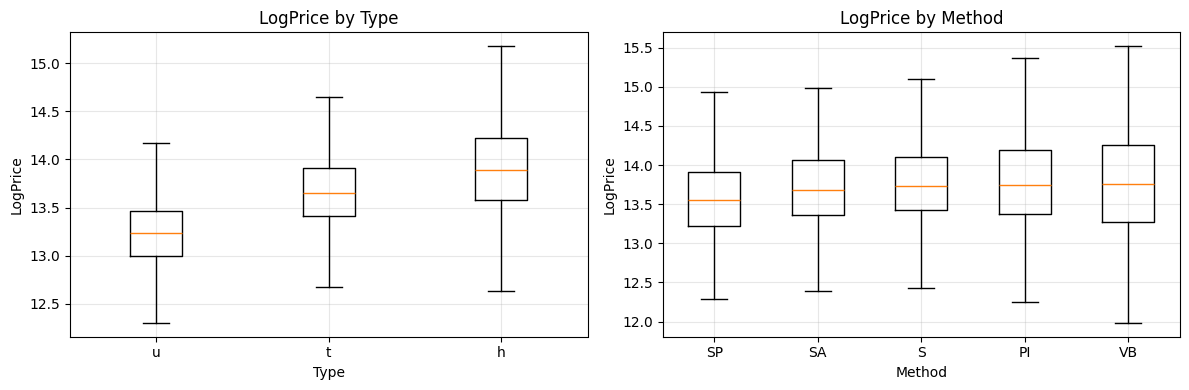

In [ ]:
def group_view(data, cat, target="LogPrice", raw="Price"):
    out = (data.groupby(cat, observed=True)
                .agg(n=(raw, "size"), mean_price=(raw, "mean"),
                     median_price=(raw, "median"), mean_log=(target, "mean"))
                .sort_values("mean_log", ascending=False))
    out[["mean_price", "median_price"]] = out[["mean_price", "median_price"]].round(0)
    out["mean_log"] = out["mean_log"].round(3)
    return out

print("=== Type ===");   print(group_view(d, "Type").to_string())
print("\n=== Method ==="); print(group_view(d, "Method").to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, cat in zip(ax, ["Type", "Method"]):
    order = d.groupby(cat, observed=True)["LogPrice"].median().sort_values().index
    a.boxplot([d.loc[d[cat] == g, "LogPrice"] for g in order],
              tick_labels=list(order), showfliers=False)
    a.set_title(f"LogPrice by {cat}")
    a.set_xlabel(cat); a.set_ylabel("LogPrice")
plt.tight_layout(); plt.show()

**Look at the two panels before reading any further.** `Type` shows three clearly offset boxes.
`Method` shows five boxes sitting almost on top of each other. Hold that picture — §9 will show that
**both** features return an overwhelmingly "significant" p-value.

---
## 3. Method 1 — ANOVA F (Do the Group **Means** Differ?)

ANOVA asks: **are the average prices of the groups different?**

| Construction | Values | Average Price |
|---|---|---|
| Concrete | 500, 520, 480 | $500k |
| Steel | 700, 680, 720 | $700k |
| Wood | 510, 490, 530 | $510k |

It answers by comparing the variation **between** groups to the variation **within** groups:

$$F = \frac{\text{variation BETWEEN groups}}{\text{variation WITHIN groups}}
    = \frac{SS_{between} / (k-1)}{SS_{within} / (n-k)}$$

where `k` = number of groups and `n` = number of observations.

* **Group means far apart, observations tightly clustered** → between is large, within is small → **F is large**.
* **Groups overlapping heavily** → between is small relative to within → **F is near 1**.

In the toy data the means are far apart ($500k / $700k / $510k) while values within each group sit
within $20k of each other — so F comes out enormous.

In [6]:
def anova_by_hand(data, cat, target):
    grand  = data[target].mean()
    groups = [g[target].values for _, g in data.groupby(cat, observed=True)]
    k, n   = len(groups), len(data)

    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_within  = sum(((g - g.mean()) ** 2).sum() for g in groups)
    ss_total   = ((data[target] - grand) ** 2).sum()

    ms_between = ss_between / (k - 1)
    ms_within  = ss_within  / (n - k)
    return {"k": k, "n": n, "SS_between": ss_between, "SS_within": ss_within,
            "SS_total": ss_total, "F": ms_between / ms_within}

h = anova_by_hand(toy, "Construction", "Price")
print("Toy data, worked by hand:")
for key in ["k", "n", "SS_between", "SS_within", "SS_total"]:
    print(f"  {key:11s} = {h[key]:,.1f}")
print(f"  F           = {h['F']:,.1f}")
print(f"\n  check: SS_between + SS_within = {h['SS_between'] + h['SS_within']:,.1f} "
      f"= SS_total ({h['SS_total']:,.1f})   <- variation always splits into exactly these two parts")

F_scipy, p_scipy = stats.f_oneway(*[g["Price"].values for _, g in toy.groupby("Construction")])
print(f"\nscipy.stats.f_oneway : F = {F_scipy:,.1f}  p = {p_scipy:.2e}   (matches the hand calculation)")

Toy data, worked by hand:
  k           = 3.0
  n           = 9.0
  SS_between  = 76,200.0
  SS_within   = 2,400.0
  SS_total    = 78,600.0
  F           = 95.2

  check: SS_between + SS_within = 78,600.0 = SS_total (78,600.0)   <- variation always splits into exactly these two parts

scipy.stats.f_oneway : F = 95.2  p = 2.85e-05   (matches the hand calculation)


### 3.1 The Problem With ANOVA: Extreme Values

ANOVA is built on **means**, and means are extremely sensitive to outliers.

| Concrete Values | Mean |
|---|---|
| 500, 510, 520 | $510 |
| 500, 510, 520, **10,000,000** | **≈ $2,500,258** |

> ⚠️ A single extreme value can massively distort a group mean, making ANOVA's conclusion unreliable
> whenever outliers are present.

The cell below does this to **real data**, and the result is worse than "unreliable" — ANOVA
completely **reverses** its verdict.

In [9]:
# 30 sales of each Type, then one absurd $50M sale added to the unit group
small = d.groupby("Type", group_keys=False).sample(n=30, random_state=1)[["Type", "Price"]]
polluted = pd.concat([small, pd.DataFrame({"Type": ["u"], "Price": [50_000_000]})], ignore_index=True)

def compare(data, label):
    groups = [g["Price"].values for _, g in data.groupby("Type")]
    F, p   = stats.f_oneway(*groups)
    H, ph  = stats.kruskal(*groups)
    grand  = data["Price"].mean()
    eta2   = (sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
              / ((data["Price"] - grand) ** 2).sum())
    return {"data": label, "ANOVA F": round(F, 2), "ANOVA p": f"{p:.2e}",
            "Kruskal H": round(H, 1), "Kruskal p": f"{ph:.2e}", "eta^2": round(eta2, 3)}

print(pd.DataFrame([compare(small, "clean (90 sales)"),
                    compare(polluted, "+ one $50M sale")]).to_string(index=False))

print("\nGroup means vs medians after the outlier:")
print(pd.DataFrame({
    "mean (clean)":     small.groupby("Type")["Price"].mean().round(0),
    "mean (polluted)":  polluted.groupby("Type")["Price"].mean().round(0),
    "median (clean)":   small.groupby("Type")["Price"].median().round(0),
    "median (polluted)": polluted.groupby("Type")["Price"].median().round(0),
}).to_string())

            data  ANOVA F  ANOVA p  Kruskal H Kruskal p  eta^2
clean (90 sales)    15.07 2.40e-06       27.6  1.01e-06  0.257
 + one $50M sale     0.41 6.65e-01       24.1  5.85e-06  0.009

Group means vs medians after the outlier:
      mean (clean)  mean (polluted)  median (clean)  median (polluted)
Type                                                                  
h        1394167.0        1394167.0       1262500.0          1262500.0
t         975340.0         975340.0        878000.0           878000.0
u         571077.0        2165558.0        549000.0           556000.0


**Read that output carefully — it is the single most important cell in this notebook.**

One bad row out of 91 took ANOVA from `F = 15.1, p = 0.0000024` — overwhelming evidence that the
types differ — to `F = 0.41, p = 0.67`, which reads as **no evidence whatsoever**. The outlier
inflated the *unit* group's mean to **$2.17M**, above the *house* group's **$1.39M** (so even the
ordering of the means is now wrong), and it exploded the within-group variance sitting in F's
denominator.

Meanwhile **Kruskal-Wallis barely moved** (`H = 27.6 → 24.1`, still `p < 0.00001`), and the group
**medians hardly budged** — the unit median went from $549,000 to $556,000, because adding one row
just shifts the middle position by one. The types obviously still differ; houses really do cost more
than units. **ANOVA simply lost the ability to see it.**

> 📌 Note the last column too: **η² collapsed from 0.257 to 0.009**. η² is built from means as well,
> so it inherits exactly the same fragility. §8.1 returns to this.

In [11]:
[g["Price"].values for _, g in small.groupby("Type")]

[array([1651000.,  722000., 3075000.,  670000., 3300000., 1291000.,
         750000.,  460000., 1350000., 1890000., 1250000., 1920000.,
        1610000.,  805000., 3400000., 1012000., 1900000., 1640000.,
        1586000., 2210000.,  691000.,  770000.,  725000.,  625000.,
         485000.,  745000., 1275000., 2500000., 1155000.,  362000.]),
 array([ 370000., 1007000.,  970000., 1011000., 1655000.,  965000.,
         707000.,  770000., 1425000., 1120000.,  670000.,  430000.,
         785000., 1264000.,  440000.,  830000.,  420000.,  610000.,
        2650000., 1710000.,  900000.,  965000.,  620500.,  856000.,
         510000., 1137000.,  731000., 2100000., 1190000.,  441700.]),
 array([ 227000.,  482300.,  570000.,  590000.,  366000.,  320500.,
         610000.,  587000.,  415000.,  600000.,  556000.,  501000.,
         520000.,  350000., 1080000.,  800000.,  627500.,  520000.,
         742500.,  315000., 1022500.,  760000.,  542000.,  740000.,
         435000.,  490000.,  686000.,  69200

---
## 4 & 5. Method 2 — Kruskal-Wallis H (Ranks Instead of Raw Values)

Kruskal-Wallis asks a subtly different question:

> **Do the groups tend to occupy different positions in the overall price *ranking*?**

This is why it is called the **non-parametric** (or robust) counterpart to ANOVA. Every price in the
whole dataset is replaced by its rank (1 = cheapest), and the test compares the **average rank** of
each group against the average rank you would expect if the labels were shuffled at random.

In the toy data, all 9 prices ranked together put Steel in ranks 7, 8, 9 — consistently at the top.

### 5.1 Why Is Kruskal-Wallis More Robust?

Take `Concrete: 500, 510, 520` and `Steel: 700, 710, 10,000,000`. The $10M value destroys the Steel
*mean*. But ranked:

| Group | Ranks |
|---|---|
| Concrete | 1, 2, 3 |
| Steel | 4, 5, 6 |

> 🧠 The extreme value is **still the largest** — but it is no longer *10,000,000 times* larger. It is
> just **rank 6**. ANOVA works with the **magnitude** of values; Kruskal-Wallis works with their
> **order**. That is the whole trick.

**The trade-off**, stated honestly: by throwing away magnitudes you also throw away information. If
your data really is well-behaved with no outliers, ANOVA is the more *powerful* test — it will detect
a genuine difference from a smaller sample. Kruskal-Wallis buys robustness with a little sensitivity.

In [13]:
print("Ranks of all 9 toy prices, pooled:")
ranked = toy.assign(rank=toy["Price"].rank()).sort_values("rank")
print(ranked[["Construction", "Price", "rank"]].to_string(index=False))
print("\nMean rank per group:")
print(ranked.groupby("Construction")["rank"].agg(["mean", "size"]).to_string())

H, pH = stats.kruskal(*[g["Price"].values for _, g in toy.groupby("Construction")])
print(f"\nKruskal-Wallis H = {H:.2f}  p = {pH:.4f}")

# --- The doc's example, made explicit ------------------------------------
demo = pd.DataFrame({"Group":  ["Concrete"]*3 + ["Steel"]*3,
                     "Value":  [500, 510, 520, 700, 710, 10_000_000]})
demo["rank"] = demo["Value"].rank()
print("\n" + demo.to_string(index=False))
print("\nMeans   :", demo.groupby("Group")["Value"].mean().round(0).to_dict())
print("Mean rank:", demo.groupby("Group")["rank"].mean().to_dict())
print("-> the mean is destroyed by 10,000,000; the rank of that value is merely 6.")

Ranks of all 9 toy prices, pooled:
Construction  Price  rank
    Concrete    480   1.0
        Wood    490   2.0
    Concrete    500   3.0
        Wood    510   4.0
    Concrete    520   5.0
        Wood    530   6.0
       Steel    680   7.0
       Steel    700   8.0
       Steel    720   9.0

Mean rank per group:
              mean  size
Construction            
Concrete       3.0     3
Steel          8.0     3
Wood           4.0     3

Kruskal-Wallis H = 5.60  p = 0.0608

   Group    Value  rank
Concrete      500   1.0
Concrete      510   2.0
Concrete      520   3.0
   Steel      700   4.0
   Steel      710   5.0
   Steel 10000000   6.0

Means   : {'Concrete': 510.0, 'Steel': 3333803.0}
Mean rank: {'Concrete': 2.0, 'Steel': 5.0}
-> the mean is destroyed by 10,000,000; the rank of that value is merely 6.


### 5.2 A Rank-Based Effect Size: ε² (epsilon-squared)

ANOVA has a natural effect size (η², next section). Kruskal-Wallis has one too, and it is worth
knowing because it is the one number in this notebook that is **both** an effect size **and**
outlier-robust:

$$\varepsilon^2 = \frac{H}{n - 1}$$

It runs from 0 to 1 and reads like η² — but computed on ranks. In the polluted example above η²
collapsed to **0.009** while ε² only drifted from **0.310 to 0.268**, because a rank does not care
*how* extreme the outlier was — only that it is last in line.

In [14]:
def epsilon2(data, cat, target):
    groups = [g[target].values for _, g in data.groupby(cat, observed=True) if len(g) > 0]
    H, p = stats.kruskal(*groups)
    return H / (len(data) - 1), H, p

for label, data in [("clean (90 sales)", small), ("+ one $50M sale", polluted)]:
    e2, H, p = epsilon2(data, "Type", "Price")
    print(f"{label:18s}  epsilon^2 = {e2:.3f}   (H = {H:.1f}, p = {p:.1e})")
print("\n-> the mean-based effect size (eta^2) collapsed 0.257 -> 0.009;")
print("   the rank-based one (epsilon^2) went 0.310 -> 0.268 and kept the same story.")

clean (90 sales)    epsilon^2 = 0.310   (H = 27.6, p = 1.0e-06)
+ one $50M sale     epsilon^2 = 0.268   (H = 24.1, p = 5.8e-06)

-> the mean-based effect size (eta^2) collapsed 0.257 -> 0.009;
   the rank-based one (epsilon^2) went 0.310 -> 0.268 and kept the same story.


---
## 6. But Neither Test Answers the Most Important Question

Suppose ANOVA returns `F = 15, p < 0.001`. You now know: *"there is evidence that the groups differ."*

You still do **not** know **how important** that difference is. A p-value is a statement about
*evidence*, and evidence is not the same thing as *magnitude*.

That is what **η²** is for.

---
## 7. Method 3 — η² (How Much Variation Does the Category Explain?)

This is the most useful single statistic for **feature screening**. η² asks:

> **What proportion of the variation in Price can be explained by knowing the category?**

$$\eta^2 = \frac{SS_{between}}{SS_{total}} = \frac{\text{variation explained by the category}}{\text{total variation}}$$

It runs from **0** (the category tells you nothing) to **1** (the category tells you everything).

### 7.1 Two Contrasting Examples

| Scenario | η² | Interpretation |
|---|---|---|
| Concrete ≈$400–500k, Steel ≈$700–800k, Wood ≈$300–400k | **0.30** | explains ~30% of price variation — potentially a very useful feature |
| Concrete=$500k, Steel=$502k, Wood=$501k | **0.001** | explains ~0.1% — not a practically useful standalone predictor |

### 7.2 η² Is Exactly the R² of a One-Hot Regression

Here is the fact that makes η² click, and that connects this notebook to `LinearityCheck.ipynb`:

> **η² for a categorical feature is identical to the R² you get from regressing the target on that
> feature's one-hot dummies.**

"Explains 28% of the variation" is not a vague phrase — it is *literally* an R². The cell below
verifies the two numbers agree to four decimals.

In [15]:
def eta2(data, cat, target="LogPrice"):
    grand  = data[target].mean()
    groups = [g[target].values for _, g in data.groupby(cat, observed=True)]
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total   = ((data[target] - grand) ** 2).sum()
    return ss_between / ss_total

print("Toy data      eta^2 =", round(eta2(toy, "Construction", "Price"), 4))
print("Real: Type    eta^2 =", round(eta2(d, "Type"), 4))
print("Real: Method  eta^2 =", round(eta2(d, "Method"), 4))

# --- the same number, via one-hot regression ----------------------------
X = pd.get_dummies(d["Type"], drop_first=True).astype(float)
r2 = LinearRegression().fit(X, d["LogPrice"]).score(X, d["LogPrice"])
print(f"\nR^2 of LogPrice ~ one-hot(Type) = {r2:.4f}")
print(f"eta^2 of Type                   = {eta2(d, 'Type'):.4f}   <- identical")

# --- the two contrasting scenarios, simulated --------------------------
big  = pd.DataFrame({"g": ["C"]*50 + ["S"]*50 + ["W"]*50,
                     "y": np.r_[rng.normal(450, 30, 50), rng.normal(750, 30, 50), rng.normal(350, 30, 50)]})
tiny = pd.DataFrame({"g": ["C"]*50 + ["S"]*50 + ["W"]*50,
                     "y": np.r_[rng.normal(500, 30, 50), rng.normal(502, 30, 50), rng.normal(501, 30, 50)]})
print(f"\nwell-separated groups : eta^2 = {eta2(big,  'g', 'y'):.3f}")
print(f"near-identical groups : eta^2 = {eta2(tiny, 'g', 'y'):.4f}")

Toy data      eta^2 = 0.9695
Real: Type    eta^2 = 0.2811
Real: Method  eta^2 = 0.0138

R^2 of LogPrice ~ one-hot(Type) = 0.2811
eta^2 of Type                   = 0.2811   <- identical

well-separated groups : eta^2 = 0.978
near-identical groups : eta^2 = 0.0016


### 7.3 Rough Interpretation Bands

Conventional (Cohen-style) rules of thumb — **triage aids, not laws** (the same caveat as §13.1 of the
linearity notebook):

| η² | Label | In practice |
|---|---|---|
| ≥ 0.14 | large | a strong feature, keep it |
| 0.06 – 0.14 | medium | useful, worth keeping |
| 0.01 – 0.06 | small | may still help in a model alongside others |
| < 0.01 | negligible | rarely worth keeping on its own |

---
## 8. Two Traps in η² You Must Know About

η² is the best of the three for screening — but it is not magic. Two things will fool it.

### 8.1 Trap 1 — η² Is Mean-Based, So Outliers Hurt It Too

We already saw this in §3.1: one $50M sale dragged η² from **0.27 to 0.01**. η² is built from
`SS_between / SS_total`, and both of those are sums of squared distances from *means*.

**The fix:** report **ε²** (§5.2) alongside η². If they disagree sharply, you have an outlier
problem, not a feature problem.

### 8.2 Trap 2 — η² Rises Automatically With the Number of Categories

This one is subtler and catches almost everyone. **More groups mechanically means more explained
variation**, even if the grouping is complete nonsense. In the limit, a category with one level per
row "explains" 100% of the variation while telling you nothing at all.

The cell below assigns every property a **completely random ID from 1–300** — pure noise, unrelated to
price by construction — and computes η².

In [16]:
d["random_300"] = rng.integers(0, 300, len(d)).astype(str)   # pure noise, 300 levels
d["random_5"]   = rng.integers(0, 5,   len(d)).astype(str)   # pure noise, 5 levels

def omega2(data, cat, target="LogPrice"):
    # Omega-squared: eta-squared with the degrees-of-freedom inflation removed.
    grand  = data[target].mean()
    groups = [g[target].values for _, g in data.groupby(cat, observed=True)]
    k, n   = len(groups), len(data)
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total   = ((data[target] - grand) ** 2).sum()
    ms_within  = (ss_total - ss_between) / (n - k)
    return (ss_between - (k - 1) * ms_within) / (ss_total + ms_within)

rows = []
for c in ["random_5", "random_300", "Method"]:
    groups = [g["LogPrice"].values for _, g in d.groupby(c, observed=True)]
    F, p = stats.f_oneway(*groups)
    rows.append({"feature": c, "levels": d[c].nunique(),
                 "eta^2": round(eta2(d, c), 4), "omega^2": round(omega2(d, c), 4),
                 "ANOVA p": f"{p:.3f}"})
print(pd.DataFrame(rows).to_string(index=False))

   feature  levels  eta^2  omega^2 ANOVA p
  random_5       5 0.0003   0.0000   0.348
random_300     300 0.0214  -0.0006   0.630
    Method       5 0.0138   0.0135   0.000


**Sit with that result.** A column of **pure random numbers** with 300 levels posts `η² = 0.021` —
*larger* than `Method`'s **0.0138**, and `Method` is a real feature describing how the property
actually sold. **Rank your features by raw η² and you would prefer the noise to the signal.**

Two things rescue you, and both are in the table:

1. **ω² (omega-squared)** — η² with the degrees-of-freedom inflation subtracted out. It drops the
   random 300-level column to **−0.0006** while leaving `Method` at **0.0135**, essentially unchanged.
   (ω² can come out slightly **negative** when the observed effect is *smaller* than chance alone
   would produce. Read any negative value as **zero** — it means "nothing here".)
2. **The p-value** — here it finally earns its keep. The random column's `p = 0.63` says the
   "explained" variation is no more than chance would produce anyway. This is the one place in the
   whole notebook where the p-value is the **more** informative number.

> 🎯 **The rule:** compare η² **only between features of similar cardinality**. Across different
> cardinalities, use **ω²**. And treat any high-cardinality feature (`Suburb`, `SellerG`, `Postcode`)
> with suspicion until you have validated it out-of-sample — those are exactly the features that
> overfit.

---
## 9. Why the p-value Can Be Misleading

With a large sample, **even a tiny, meaningless difference becomes "statistically significant."**

Suppose you have n = 8,623 properties, Concrete averages $500,000 and Steel averages $501,000 — a
difference of **$1,000, or 0.2%**. With thousands of observations a test detects that difference
confidently and reports `p < 0.001`.

> ⚠️ `p < 0.001` means **"this difference is unlikely to be pure sampling noise."**
> It does **not** mean **"this difference is large."** Two completely different questions.

### 9.1 Statistical Significance vs Practical Significance

| Feature | p-value | η² | Interpretation |
|---|---|---|---|
| Feature A | 0.000001 | 0.0001 | very significant, explains **almost nothing** |
| Feature B | 0.000001 | 0.15 | very significant **and** explains substantial variation |

The cell below demonstrates the mechanism directly: it takes the **same feature** (`Method`) and
computes both statistics on growing samples. Watch η² stay flat while p falls off a cliff.

In [17]:
rows = []
for n in [50, 200, 1000, 5000, len(d)]:
    s = d.sample(n, random_state=3)
    groups = [g["LogPrice"].values for _, g in s.groupby("Method", observed=True) if len(g) > 1]
    F, p = stats.f_oneway(*groups)
    rows.append({"sample size": n, "ANOVA F": round(F, 2), "p-value": f"{p:.2e}",
                 "significant?": "YES" if p < 0.05 else "no",
                 "eta^2": round(eta2(s, "Method"), 4)})
print(pd.DataFrame(rows).to_string(index=False))

print("\nThe effect size barely moves. The p-value travels from 'no evidence' to 1e-40.")
print("Nothing about the FEATURE changed - only how much data we had to detect it.")

 sample size  ANOVA F  p-value significant?  eta^2
          50     0.74 5.36e-01           no 0.0458
         200     2.29 6.08e-02           no 0.0449
        1000     4.69 9.47e-04          YES 0.0185
        5000    17.17 5.33e-14          YES 0.0136
       13580    47.59 8.41e-40          YES 0.0138

The effect size barely moves. The p-value travels from 'no evidence' to 1e-40.
Nothing about the FEATURE changed - only how much data we had to detect it.


> 🎯 With ~13,600 observations, pay far more attention to **effect size (η²)** than to the p-value.
> At this sample size the p-value has stopped being a screening tool: almost everything is
> "significant". `Method` posts `p = 8e-40` — a number so small it looks like proof of importance —
> and explains **1.4%** of price variation.

Return to the boxplots in §2.1: `Method`'s five boxes visibly overlap. That picture was right, and
`p = 8e-40` was never in conflict with it — the two were answering different questions all along.

---
## 10. What Each Statistic Is Really Telling You

| Statistic | Simple question | Example answer | Robust? |
|---|---|---|---|
| **ANOVA F** | Are group **means** separated relative to within-group noise? | "the Steel mean is much higher" | ❌ |
| **Kruskal-Wallis H** | Do groups occupy different **ranks/positions**? | "Steel tends to have higher prices" | ✅ |
| **η² (eta-squared)** | **How much** price variation does the category explain? | "Construction explains 8%" | ❌ |
| **ε² (epsilon-squared)** | Same, computed on ranks | "about 8%, and outliers can't fake it" | ✅ |
| **ω² (omega-squared)** | Same, corrected for number of levels | "3%, not 25% — that was cardinality" | ❌ |
| **p-value** | Could the observed difference plausibly be random? | "very unlikely" | — |

### 9.2 / 10.1 Why Both Tests Still Matter

| Pattern | Meaning |
|---|---|
| ANOVA significant, Kruskal significant, η² large | **strong evidence — the difference is real AND important** |
| ANOVA significant, Kruskal significant, η² tiny | the difference is **real but unimportant** on its own |
| ANOVA **not** significant, Kruskal significant | suspect **outliers** — trust Kruskal, go look at your data |
| η² large, ω² small | suspect **cardinality inflation** — too many levels |
| Both tests significant, η² large, but the feature has 300 levels | plausible, but **validate out-of-sample** before believing it |

It would be too strong to say "only one of the three is useful". The accurate statement is:

> 🎯 For **feature-strength assessment**, η² is the most directly useful of the three because it
> measures **effect size**. ANOVA F and Kruskal-Wallis H are valuable as **significance tests** and,
> read together, as an **outlier diagnostic**.

---
## 11. Applied Example — Screening Multiple Categorical Features

This is what the whole notebook was building towards: **one function that screens every categorical
column and ranks them by what actually matters.**

In [18]:
def categorical_report(data, cats, target="LogPrice"):
    rows = []
    for c in cats:
        sub    = data.dropna(subset=[c])
        groups = [g[target].values for _, g in sub.groupby(c, observed=True) if len(g) > 1]
        F,  p  = stats.f_oneway(*groups)
        H, ph  = stats.kruskal(*groups)
        e2 = eta2(sub, c, target)
        w2 = omega2(sub, c, target)
        eps = H / (len(sub) - 1)

        # Groups with a single observation carry no within-group variance and are dropped
        # by the tests above - 'used' records how many groups actually entered the statistics.
        if   e2 >= 0.14: size = "large"
        elif e2 >= 0.06: size = "medium"
        elif e2 >= 0.01: size = "small"
        else:            size = "negligible"

        # The ratio-based flags are only meaningful once there is some effect to compare,
        # so they are gated on eta^2 >= 0.01 (below that, both numbers are just noise).
        flags = []
        if e2 >= 0.01 and w2 < e2 * 0.75:  flags.append("cardinality-inflated")
        if e2 >= 0.01 and eps < e2 * 0.6:  flags.append("outlier-sensitive")
        if p >= 0.05:                      flags.append("not significant")
        if len(groups) > 50:               flags.append("high-cardinality: validate OOS")

        rows.append({"feature": c, "levels": sub[c].nunique(), "used": len(groups),
                     "ANOVA F": round(F, 1), "ANOVA p": f"{p:.1e}",
                     "Kruskal H": round(H, 1), "Kruskal p": f"{ph:.1e}",
                     "eta^2": round(e2, 4), "omega^2": round(w2, 4), "eps^2": round(eps, 4),
                     "effect": size, "flags": ", ".join(flags) or "-"})

    return (pd.DataFrame(rows)
              .sort_values("omega^2", ascending=False)
              .reset_index(drop=True))

report = categorical_report(d, CATS + ["random_300", "random_5"])
print(report.to_string(index=False))

    feature  levels  used  ANOVA F ANOVA p  Kruskal H Kruskal p  eta^2  omega^2  eps^2     effect                                                                 flags
     Suburb     314   293     21.5 0.0e+00     4598.5   0.0e+00 0.3225   0.3065 0.3386      large                                        high-cardinality: validate OOS
       Type       3     3   2654.2 0.0e+00     3977.6   0.0e+00 0.2811   0.2810 0.2929      large                                                                     -
CouncilArea      33    31     99.3 0.0e+00     2457.7   0.0e+00 0.1968   0.1947 0.2013      large                                                                     -
    SellerG     268   190     18.2 0.0e+00     2667.6   0.0e+00 0.2103   0.1945 0.1964      large                                        high-cardinality: validate OOS
 Regionname       8     8    252.9 0.0e+00     1499.5   0.0e+00 0.1154   0.1149 0.1104     medium                                                               

### 11.1 Reading the Screening Table

| Feature | levels | η² | ω² | Verdict |
|---|---|---|---|---|
| `Suburb` | 314 | 0.323 | 0.307 | highest η² — but 314 levels, so **validate out-of-sample** and expect to need grouping or target encoding |
| `Type` | 3 | 0.281 | 0.281 | **the most trustworthy feature here.** η² = ω² to three decimals, only 3 levels, nothing to distrust |
| `CouncilArea` | 33 | 0.197 | 0.195 | strong and well behaved |
| `SellerG` | 268 | 0.210 | 0.195 | η² − ω² = 0.015, the largest gap in the table — some of that 0.21 **is** cardinality |
| `Regionname` | 8 | 0.115 | 0.115 | solid, well behaved, cheap to encode |
| `Method` | 5 | 0.0138 | 0.0135 | **the trap.** `p = 8e-40` and explains **1.4%** |
| `random_300` | 300 | 0.021 | **−0.0006** | **caught.** Only ω² and the p-value (0.63) expose it |
| `random_5` | 5 | 0.0003 | 0.0000 | correctly rejected by everything |

**The three lessons in one table:**

1. **`Method` vs `random_300`** — ranked by raw η², *random noise* beats a *real feature*. Ranked by
   ω², the ordering corrects itself. That is why this report sorts by **ω²**, not η².
2. **η² ≈ ε² for every real feature here**, which is the all-clear from §8.1: no effect size in this
   table is resting on a handful of extreme sales. Had one shown ε² far below η², that feature would
   need investigating before being trusted.
3. **`Type`'s 0.281 is worth more than `Suburb`'s 0.323.** Three levels that explain 28% is a cheap,
   robust, generalisable signal; 314 levels that explain 32% is a *promise* that has to be verified —
   which is exactly what the next cell does. Effect size is where ranking **starts**, not where it
   ends.

> ⚠️ **The `Method` / Zoning trap, stated plainly:** `Method` is significant at `p = 8e-40` and
> explains **1.4%** of price variation. Ranking features by p-value would put it near the top of your
> list. Ranking by effect size puts it where it belongs.

In [20]:
# Does SellerG survive once Regionname is accounted for? Effect size alone cannot say -
# this is the multivariate question, and it needs a model (cf. LinearityCheck.ipynb 13.2).
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
y  = d["LogPrice"]

def cv_r2(cols):
    X = pd.get_dummies(d[cols].astype(str), drop_first=True).astype(float)
    return cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2").mean()

print(f"Type                          : CV R^2 = {cv_r2(['Type']):.4f}")
print(f"Type + Regionname             : CV R^2 = {cv_r2(['Type', 'Regionname']):.4f}")
print(f"Type + Regionname + SellerG   : CV R^2 = {cv_r2(['Type', 'Regionname', 'SellerG']):.4f}")
print(f"Type + Regionname + random_300: CV R^2 = {cv_r2(['Type', 'Regionname', 'random_300']):.4f}")
print("\nThe noise column had eta^2 = 0.021 in-sample. Out-of-sample it does not merely fail")
print("to help - it makes the model WORSE, by fitting 300 levels of pure noise.")
print("Screening proposes; validation decides.")

Type                          : CV R^2 = 0.2807
Type + Regionname             : CV R^2 = 0.4758
Type + Regionname + SellerG   : CV R^2 = 0.5530
Type + Regionname + random_300: CV R^2 = 0.4604

The noise column had eta^2 = 0.021 in-sample. Out-of-sample it does not merely fail
to help - it makes the model WORSE, by fitting 300 levels of pure noise.
Screening proposes; validation decides.


### 11.2 What the Validation Actually Said

Two results worth separating, because they point in opposite directions:

* **`SellerG` earned its place.** Adding it lifted cross-validated R² from **0.476 to 0.553** — a
  real, substantial gain, even though it has 268 levels and the largest η²/ω² gap in the table.
  "High cardinality" is a reason to **verify**, not a reason to discard. Here the verification passed.
* **`random_300` did not.** Same high cardinality, same in-sample η² of 0.021 — and out-of-sample it
  *degraded* the model (0.476 → 0.460).

Those two columns look similar in a screening table. **Only out-of-sample validation separates them.**
That is the entire argument for step 7 of the checklist below.

> 📌 One caveat on `SellerG` worth keeping in mind: an agency's identity is partly a **proxy** for the
> areas it operates in. Its gain here is real, but some of it is location signal arriving under a
> different name — which matters if you later interpret its coefficients rather than just predicting.

---
## 12. Remember: η² Isn't "Linearity"

For a **numerical** feature you investigate Pearson, Spearman, and linear-vs-nonlinear shape.
For a **categorical** feature you investigate **group differences**. Different question, different
tools, different failure modes.

```
                          ┌──────────────────────┐
                          │   a feature X        │
                          └──────────┬───────────┘
                                     ↓
                    ┌────────────────┴────────────────┐
                    ↓                                 ↓
             NUMERICAL                          CATEGORICAL
                    ↓                                 ↓
        "is it a straight line?"        "do the groups differ, and how much?"
                    ↓                                 ↓
        scatter + binned medians              group means / medians / counts
        Pearson  vs  Spearman                 ANOVA F   +   Kruskal-Wallis H
        log / sqrt / squared term             eta^2  (+ omega^2, epsilon^2)
                    ↓                                 ↓
                    └────────────────┬────────────────┘
                                     ↓
                       validate OUT-OF-SAMPLE (cross-validated R^2)
                                     ↓
                                final model
```

Note the shared final step. In both branches every statistic before it only **proposes a
hypothesis** — cross-validation is what decides.

---
## 13. The Practical Takeaway

> 🚀 **Don't rank categorical features by p-value.** Rank them primarily by **effect size**, using
> ANOVA and Kruskal-Wallis to check whether the differences are statistically detectable and whether
> the result is **robust to outliers**.

### Quick checklist for any categorical feature

1. **Look at the groups.** Group means, medians **and counts**. Most problems are visible here — and
   counts warn you about groups too small to trust (`Method`'s `SA` has just 92 rows).
2. **Run ANOVA F.** Is there evidence the means genuinely differ?
3. **Run Kruskal-Wallis H.** Does the conclusion survive without relying on magnitudes? If ANOVA and
   Kruskal **disagree**, stop and go find your outliers.
4. **Calculate η².** How much of the target's variation does the category actually explain?
5. **Check ω² next to η².** A big gap means the effect size is inflated by having many levels.
6. **Rank by effect size, not by p-value.** A feature with tiny η² is rarely worth keeping, however
   small its p-value.
7. **Validate out-of-sample.** Especially for high-cardinality features — screening statistics are
   computed in-sample, and in-sample is exactly where they lie to you.

### One-line summary

> 🎯 A categorical feature check is not a significance test. It is the process of comparing groups,
> confirming the comparison is robust to outliers, measuring **how much** variation the category
> explains, correcting that measure for the number of levels — and then verifying out-of-sample that
> the feature earns its place.

🚀 **Keep Learning & Keep Exploring!**